1 proceso(s): 2.985 s  (corridas: 5.830, 2.952, 2.942, 3.782, 5.143, 2.985, 2.980)
2 proceso(s): 3.210 s  (corridas: 3.172, 4.753, 3.190, 3.181, 3.224, 4.820, 3.210)
4 proceso(s): 3.738 s  (corridas: 3.209, 3.356, 4.578, 3.738, 4.007, 4.684, 3.493)
8 proceso(s): 3.229 s  (corridas: 3.227, 3.221, 4.807, 3.289, 3.221, 3.229, 5.049)

Procesos | Tiempo (s) | Speedup | Eficiencia
       1 |      2.985 |    1.00 |      100%
       2 |      3.210 |    0.93 |       46%
       4 |      3.738 |    0.80 |       20%
       8 |      3.229 |    0.92 |       12%

Nucleos detectados: 2
Grafica guardada en speedup.png


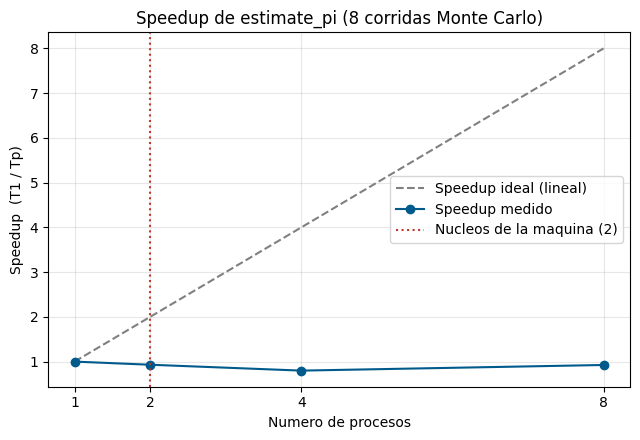

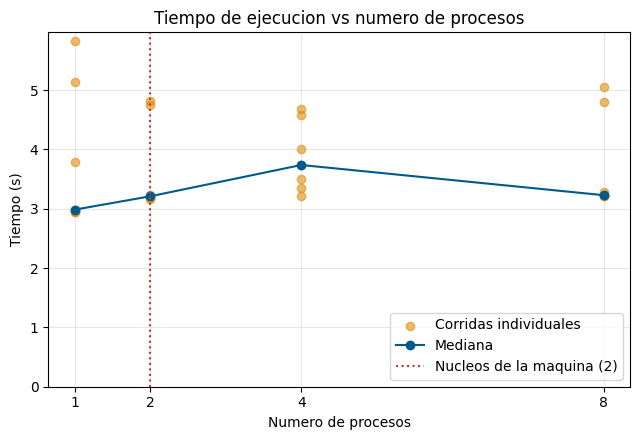

In [1]:
#Ejercicio No.1
import json
import multiprocessing as mp
import random
import statistics
import time

import matplotlib.pyplot as plt


def estimate_pi(seed: int, samples: int = 1_000_000) -> float:
    rng = random.Random(seed)
    inside = sum(rng.random()**2 + rng.random()**2 <= 1.0
                 for _ in range(samples))
    return 4 * inside / samples


def run_with(processes: int, seeds: list[int]) -> float:
    t0 = time.perf_counter()
    with mp.Pool(processes=processes) as pool:
        pool.map(estimate_pi, seeds)
    return time.perf_counter() - t0


if __name__ == "__main__":
    seeds = list(range(8))
    process_counts = [1, 2, 4, 8]
    repeats = 7

    run_with(2, seeds)

    times = {}
    all_runs = {}
    for p in process_counts:
        runs = [run_with(p, seeds) for _ in range(repeats)]
        times[p] = statistics.median(runs)
        all_runs[p] = runs
        print(f"{p} proceso(s): {times[p]:.3f} s  (corridas: "
              f"{', '.join(f'{r:.3f}' for r in runs)})")

    t1 = times[1]
    speedups = {p: t1 / times[p] for p in process_counts}
    efficiency = {p: speedups[p] / p for p in process_counts}

    print("\nProcesos | Tiempo (s) | Speedup | Eficiencia")
    for p in process_counts:
        print(f"{p:>8} | {times[p]:>10.3f} | {speedups[p]:>7.2f} | {efficiency[p]:>9.0%}")

    cores = mp.cpu_count()
    print(f"\nNucleos detectados: {cores}")

    with open("resultados.json", "w") as f:
        json.dump({"cores": cores, "times": times, "speedups": speedups}, f)

    plt.figure(figsize=(6.5, 4.5))
    plt.plot(process_counts, process_counts, "--", color="gray", label="Speedup ideal (lineal)")
    plt.plot(process_counts, [speedups[p] for p in process_counts],
             "o-", color="#005A8C", label="Speedup medido")
    plt.axvline(cores, color="#C0392B", linestyle=":", label=f"Nucleos de la maquina ({cores})")
    plt.xlabel("Numero de procesos")
    plt.ylabel("Speedup  (T1 / Tp)")
    plt.title("Speedup de estimate_pi (8 corridas Monte Carlo)")
    plt.xticks(process_counts)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("speedup.png", dpi=150)
    print("Grafica guardada en speedup.png")

    plt.figure(figsize=(6.5, 4.5))
    for p in process_counts:
        plt.scatter([p] * len(all_runs[p]), all_runs[p], color="#E08E0B", alpha=0.6,
                    label="Corridas individuales" if p == process_counts[0] else None)
    plt.plot(process_counts, [times[p] for p in process_counts],
             "o-", color="#005A8C", label="Mediana")
    plt.axvline(cores, color="#C0392B", linestyle=":", label=f"Nucleos de la maquina ({cores})")
    plt.xlabel("Numero de procesos")
    plt.ylabel("Tiempo (s)")
    plt.title("Tiempo de ejecucion vs numero de procesos")
    plt.xticks(process_counts)
    plt.ylim(bottom=0)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


Instancia del documento
Capacidad W = 50
  A: v= 60  w=10  v/w=6.00
  B: v=100  w=20  v/w=5.00
  C: v=120  w=30  v/w=4.00
  Voraz por v/w      : valor 160  items ['A', 'B']
  Voraz menor peso   : valor 160  items ['A', 'B']
  Optimo (DP)        : valor 220  items ['B', 'C']

Instancia propia (menor peso pierde)
Capacidad W = 6
  A: v=  1  w= 1  v/w=1.00
  B: v=  2  w= 2  v/w=1.00
  C: v= 10  w= 5  v/w=2.00
  Voraz por v/w      : valor  11  items ['A', 'C']
  Voraz menor peso   : valor   3  items ['A', 'B']
  Optimo (DP)        : valor  11  items ['A', 'C']

Instancia nueva: el voraz por v/w queda atorado en un optimo local
Capacidad W = 8
  A: v=  3  w= 2  v/w=1.50
  B: v=  7  w= 2  v/w=3.50
  C: v= 12  w= 5  v/w=2.40
  D: v=  5  w= 2  v/w=2.50
  Voraz por v/w: valor 15  items ['A', 'B', 'D']  peso usado 6 de 8
  Vecinos factibles (agregar/quitar un objeto, o cambiar uno por otro):
    ['B', 'D']  valor 12
    ['A', 'D']  valor 8
    ['A', 'B']  valor 10
  Algun vecino mejora? NO -> op

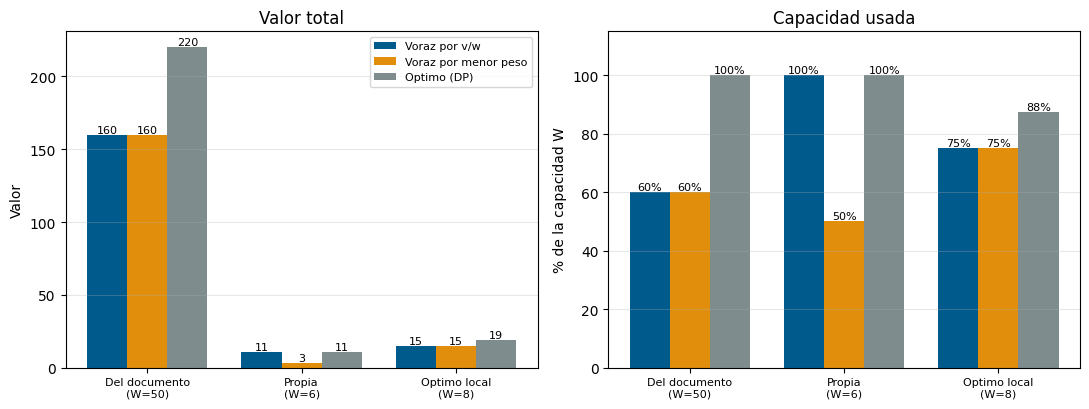

In [2]:
#Ejercicio No.2
import json
import random

import matplotlib.pyplot as plt


def knapsack(values, weights, W):
    n = len(values)
    K = [[0] * (W + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        v, w = values[i - 1], weights[i - 1]
        for c in range(W + 1):
            K[i][c] = K[i - 1][c]
            if w <= c:
                K[i][c] = max(K[i][c], v + K[i - 1][c - w])
    chosen, c = [], W
    for i in range(n, 0, -1):
        if K[i][c] != K[i - 1][c]:
            chosen.append(i - 1)
            c -= weights[i - 1]
    return K, K[n][W], chosen[::-1]


def greedy(values, weights, W, key):
    order = sorted(range(len(values)), key=key)
    total_w, total_v, chosen = 0, 0, []
    for i in order:
        if total_w + weights[i] <= W:
            chosen.append(i)
            total_w += weights[i]
            total_v += values[i]
    return total_v, sorted(chosen)


def greedy_ratio(values, weights, W):
    return greedy(values, weights, W, key=lambda i: -values[i] / weights[i])


def greedy_weight(values, weights, W):
    return greedy(values, weights, W, key=lambda i: weights[i])


def show(titulo, items, values, weights, W):
    print(titulo)
    print("Capacidad W =", W)
    for name, v, w in zip(items, values, weights):
        print(f"  {name}: v={v:>3}  w={w:>2}  v/w={v / w:.2f}")
    vr, cr = greedy_ratio(values, weights, W)
    vw, cw = greedy_weight(values, weights, W)
    _, vo, co = knapsack(values, weights, W)
    print(f"  Voraz por v/w      : valor {vr:>3}  items {[items[i] for i in cr]}")
    print(f"  Voraz menor peso   : valor {vw:>3}  items {[items[i] for i in cw]}")
    print(f"  Optimo (DP)        : valor {vo:>3}  items {[items[i] for i in co]}")
    print()


def vecinos(sel, values, weights, W):
    n = len(values)
    out = []
    for i in range(n):
        nuevo = set(sel) ^ {i}
        if sum(weights[j] for j in nuevo) <= W:
            out.append(nuevo)
    for i in sel:
        for j in range(n):
            if j not in sel:
                nuevo = (set(sel) - {i}) | {j}
                if sum(weights[k] for k in nuevo) <= W:
                    out.append(nuevo)
    return out


def mejor_vecino(sel, values, weights, W):
    valor = sum(values[i] for i in sel)
    mejor, mejor_v = None, valor
    for nb in vecinos(sel, values, weights, W):
        v = sum(values[i] for i in nb)
        if v > mejor_v:
            mejor, mejor_v = nb, v
    return mejor, mejor_v


def show_local_optimum(titulo, items, values, weights, W):
    print(titulo)
    print("Capacidad W =", W)
    for name, v, w in zip(items, values, weights):
        print(f"  {name}: v={v:>3}  w={w:>2}  v/w={v / w:.2f}")
    vr, cr = greedy_ratio(values, weights, W)
    _, vo, co = knapsack(values, weights, W)
    sel = set(cr)
    peso = sum(weights[i] for i in sel)
    print(f"  Voraz por v/w: valor {vr}  items {[items[i] for i in cr]}  peso usado {peso} de {W}")
    print("  Vecinos factibles (agregar/quitar un objeto, o cambiar uno por otro):")
    for nb in vecinos(sel, values, weights, W):
        print(f"    {sorted(items[i] for i in nb)}  valor {sum(values[i] for i in nb)}")
    nb, v = mejor_vecino(sel, values, weights, W)
    print("  Algun vecino mejora?", "SI" if nb else "NO -> optimo local")
    print(f"  Optimo (DP): valor {vo}  items {[items[i] for i in co]}")
    print()


def filas_comparacion(nombre, items, values, weights, W):
    vr, cr = greedy_ratio(values, weights, W)
    vw, cw = greedy_weight(values, weights, W)
    _, vo, co = knapsack(values, weights, W)
    filas = []
    for metodo, v, ch in [("Voraz por v/w", vr, cr), ("Voraz por menor peso", vw, cw), ("Optimo (DP)", vo, co)]:
        filas.append({"instancia": nombre, "metodo": metodo,
                      "objetos": ", ".join(items[i] for i in ch),
                      "peso": sum(weights[i] for i in ch), "W": W, "valor": v})
    return filas


def tabla_y_barras(instancias):
    filas = []
    for nombre, items, values, weights, W in instancias:
        filas += filas_comparacion(nombre, items, values, weights, W)
    print("Tabla comparativa (objetos seleccionados, capacidad usada y valor total):")
    print(f"{'Instancia':<26}{'Metodo':<24}{'Objetos':<12}{'Capacidad usada':>16}{'Valor':>7}")
    for f in filas:
        print(f"{f['instancia']:<26}{f['metodo']:<24}{f['objetos']:<12}{str(f['peso']) + ' de ' + str(f['W']):>16}{f['valor']:>7}")
    print()
    with open("tabla_ej2.json", "w") as fh:
        json.dump(filas, fh)

    nombres = [i[0] for i in instancias]
    metodos = ["Voraz por v/w", "Voraz por menor peso", "Optimo (DP)"]
    colores = ["#005A8C", "#E08E0B", "#7F8C8D"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ancho = 0.26
    for k, (m, c) in enumerate(zip(metodos, colores)):
        vals = [next(f["valor"] for f in filas if f["instancia"] == n and f["metodo"] == m) for n in nombres]
        uso = [next(f["peso"] / f["W"] * 100 for f in filas if f["instancia"] == n and f["metodo"] == m) for n in nombres]
        xs = [j + (k - 1) * ancho for j in range(len(nombres))]
        b1 = axes[0].bar(xs, vals, ancho, color=c, label=m)
        b2 = axes[1].bar(xs, uso, ancho, color=c, label=m)
        axes[0].bar_label(b1, fontsize=8)
        axes[1].bar_label(b2, fmt="%.0f%%", fontsize=8)
    for ax, t, yl in zip(axes, ["Valor total", "Capacidad usada"], ["Valor", "% de la capacidad W"]):
        ax.set_xticks(range(len(nombres)))
        ax.set_xticklabels([n.replace(" (", "\n(") for n in nombres], fontsize=8)
        ax.set_title(t)
        ax.set_ylabel(yl)
        ax.grid(axis="y", alpha=0.3)
    axes[1].set_ylim(0, 115)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig("ej2_barras.png", dpi=150)


if __name__ == "__main__":
    show("Instancia del documento", ["A", "B", "C"], [60, 100, 120], [10, 20, 30], 50)
    show("Instancia propia (menor peso pierde)", ["A", "B", "C"], [1, 2, 10], [1, 2, 5], 6)

    show_local_optimum("Instancia nueva: el voraz por v/w queda atorado en un optimo local",
                       ["A", "B", "C", "D"], [3, 7, 12, 5], [2, 2, 5, 2], 8)

    tabla_y_barras([
        ("Del documento (W=50)", ["A", "B", "C"], [60, 100, 120], [10, 20, 30], 50),
        ("Propia (W=6)", ["A", "B", "C"], [1, 2, 10], [1, 2, 5], 6),
        ("Optimo local (W=8)", ["A", "B", "C", "D"], [3, 7, 12, 5], [2, 2, 5, 2], 8),
    ])

    random.seed(2024)
    trials = 10_000
    peor = mejor = igual = 0
    for _ in range(trials):
        n = random.randint(3, 8)
        weights = [random.randint(1, 15) for _ in range(n)]
        values = [random.randint(1, 30) for _ in range(n)]
        W = max(5, sum(weights) // 2)
        vr, _ = greedy_ratio(values, weights, W)
        vw, _ = greedy_weight(values, weights, W)
        if vw < vr:
            peor += 1
        elif vw > vr:
            mejor += 1
        else:
            igual += 1
    print(f"{trials} instancias aleatorias (3 a 8 objetos):")
    print(f"  menor peso PEOR que v/w : {peor} ({peor / trials:.1%})")
    print(f"  menor peso IGUAL        : {igual} ({igual / trials:.1%})")
    print(f"  menor peso MEJOR        : {mejor} ({mejor / trials:.1%})")
    plt.show()


Ejemplo de 5 ciudades del documento:
  inicio ['A', 'D', 'E', 'B', 'C']  L = 19.66
  final  ['A', 'B', 'E', 'D', 'C']  L = 15.66  mejoras = 1

n = 20 ciudades, 100 instancias
  Mejoras 2-opt, desde Nearest Neighbour: media    6.1  mediana   5.0  min 0  max 18
  Mejoras 2-opt, desde tour aleatorio   : media   31.5  mediana  31.5  min 20  max 42
  NN necesito menos mejoras en 100 de 100 instancias
  Longitud inicial media : NN   44.19   aleatorio  102.18
  Longitud final media   : NN   38.73   aleatorio   39.24
  Tour final mas corto: con NN 44 veces, con aleatorio 32 veces

n = 40 ciudades, 100 instancias
  Mejoras 2-opt, desde Nearest Neighbour: media   13.8  mediana  13.0  min 3  max 31
  Mejoras 2-opt, desde tour aleatorio   : media   87.3  mediana  87.5  min 58  max 115
  NN necesito menos mejoras en 100 de 100 instancias
  Longitud inicial media : NN   63.22   aleatorio  209.63
  Longitud final media   : NN   54.72   aleatorio   54.81
  Tour final mas corto: con NN 52 veces, con al

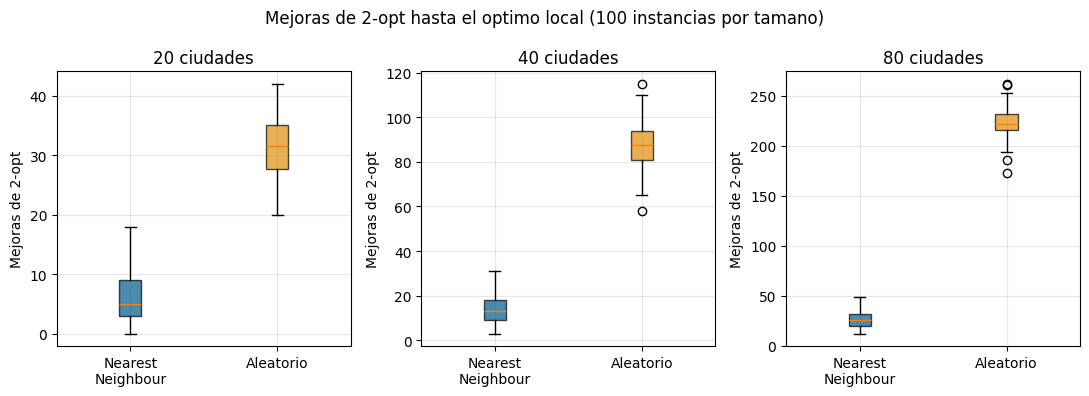

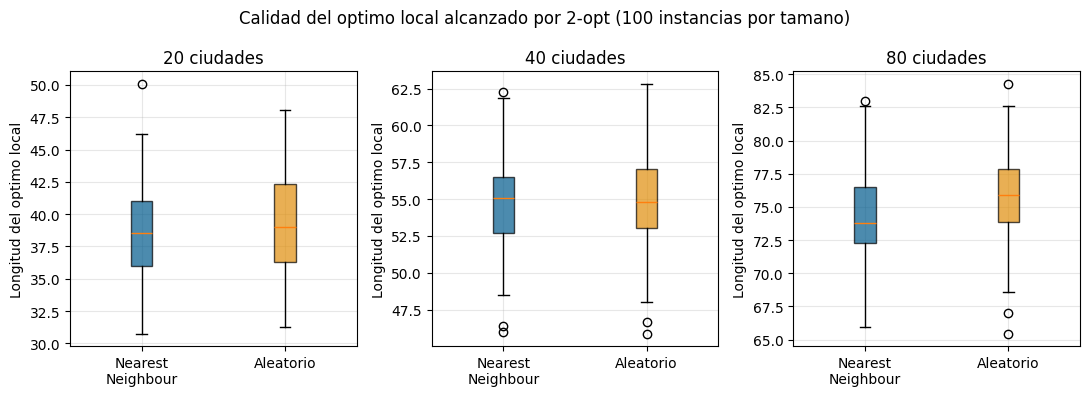

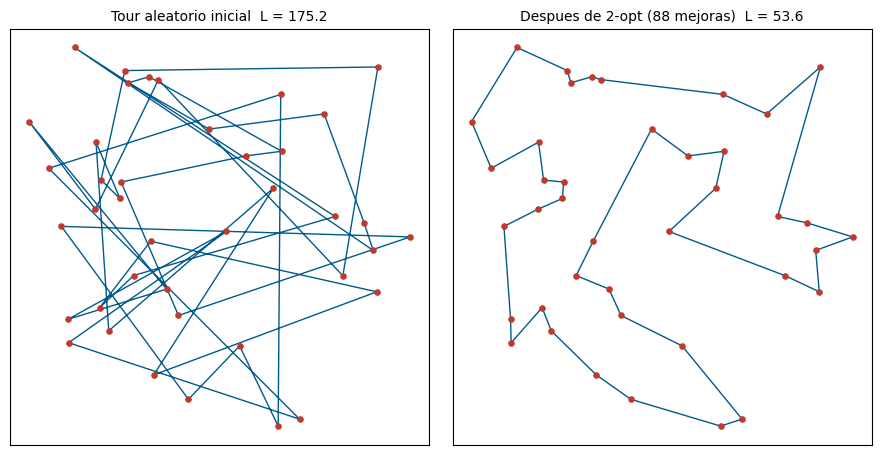

In [14]:
#Ejercicio No.3 (1)
import math
import random
import statistics

import matplotlib.pyplot as plt

EPS = 1e-9


def tour_length(points, route):
    return sum(math.dist(points[route[i]], points[route[(i + 1) % len(route)]])
               for i in range(len(route)))


def two_opt_move(route, i, k):
    return route[:i] + route[i:k + 1][::-1] + route[k + 1:]


def two_opt(points, route):
    route = route[:]
    n = len(route)
    improvements = 0
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for k in range(i + 1, n):
                a, b = points[route[i - 1]], points[route[i]]
                c, d = points[route[k]], points[route[(k + 1) % n]]
                delta = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
                if delta < -EPS:
                    route = two_opt_move(route, i, k)
                    improvements += 1
                    improved = True
    return route, improvements


def nearest_neighbour(points, start):
    unvisited = set(range(len(points))) - {start}
    route = [start]
    while unvisited:
        last = points[route[-1]]
        nxt = min(unvisited, key=lambda j: math.dist(last, points[j]))
        route.append(nxt)
        unvisited.remove(nxt)
    return route


def random_tour(points, rng):
    route = list(range(len(points)))
    rng.shuffle(route)
    return route


def run_instance(n, rng):
    points = [(rng.uniform(0, 10), rng.uniform(0, 10)) for _ in range(n)]
    nn = nearest_neighbour(points, start=rng.randrange(n))
    rt = random_tour(points, rng)
    nn_final, nn_imp = two_opt(points, nn)
    rt_final, rt_imp = two_opt(points, rt)
    return {
        "points": points,
        "nn_start": tour_length(points, nn), "nn_imp": nn_imp,
        "nn_final": tour_length(points, nn_final),
        "rt_start": tour_length(points, rt), "rt_imp": rt_imp,
        "rt_final": tour_length(points, rt_final),
        "rt_route": rt, "rt_final_route": rt_final,
    }


def draw_tour(ax, points, route, title):
    xs = [points[i][0] for i in route] + [points[route[0]][0]]
    ys = [points[i][1] for i in route] + [points[route[0]][1]]
    ax.plot(xs, ys, "-", color="#005A8C", linewidth=1)
    ax.scatter([p[0] for p in points], [p[1] for p in points], color="#C0392B", s=14, zorder=3)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


if __name__ == "__main__":
    cities = {"A": (0, 0), "B": (0, 3), "E": (2, 5), "D": (4, 3), "C": (4, 0)}
    names = list(cities)
    pts = [cities[k] for k in names]
    start = [names.index(c) for c in ["A", "D", "E", "B", "C"]]
    final, imp = two_opt(pts, start)
    print("Ejemplo de 5 ciudades del documento:")
    print(f"  inicio {[names[i] for i in start]}  L = {tour_length(pts, start):.2f}")
    print(f"  final  {[names[i] for i in final]}  L = {tour_length(pts, final):.2f}  mejoras = {imp}")
    print()

    sizes = [20, 40, 80]
    instances = 100
    rng = random.Random(2024)
    results = {}
    first_example = None

    for n in sizes:
        rows = [run_instance(n, rng) for _ in range(instances)]
        results[n] = rows
        if n == 40 and first_example is None:
            first_example = rows[0]
        nn_imp = [r["nn_imp"] for r in rows]
        rt_imp = [r["rt_imp"] for r in rows]
        fewer = sum(1 for r in rows if r["nn_imp"] < r["rt_imp"])
        nn_better = sum(1 for r in rows if r["nn_final"] < r["rt_final"] - EPS)
        rt_better = sum(1 for r in rows if r["rt_final"] < r["nn_final"] - EPS)
        print(f"n = {n} ciudades, {instances} instancias")
        print(f"  Mejoras 2-opt, desde Nearest Neighbour: media {statistics.mean(nn_imp):6.1f}  mediana {statistics.median(nn_imp):5.1f}  min {min(nn_imp)}  max {max(nn_imp)}")
        print(f"  Mejoras 2-opt, desde tour aleatorio   : media {statistics.mean(rt_imp):6.1f}  mediana {statistics.median(rt_imp):5.1f}  min {min(rt_imp)}  max {max(rt_imp)}")
        print(f"  NN necesito menos mejoras en {fewer} de {instances} instancias")
        print(f"  Longitud inicial media : NN {statistics.mean(r['nn_start'] for r in rows):7.2f}   aleatorio {statistics.mean(r['rt_start'] for r in rows):7.2f}")
        print(f"  Longitud final media   : NN {statistics.mean(r['nn_final'] for r in rows):7.2f}   aleatorio {statistics.mean(r['rt_final'] for r in rows):7.2f}")
        print(f"  Tour final mas corto: con NN {nn_better} veces, con aleatorio {rt_better} veces")
        print()

    fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=False)
    for ax, n in zip(axes, sizes):
        rows = results[n]
        data = [[r["nn_imp"] for r in rows], [r["rt_imp"] for r in rows]]
        bp = ax.boxplot(data, tick_labels=["Nearest\nNeighbour", "Aleatorio"], patch_artist=True)
        for patch, color in zip(bp["boxes"], ["#005A8C", "#E08E0B"]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(f"{n} ciudades")
        ax.set_ylabel("Mejoras de 2-opt")
        ax.grid(alpha=0.3)
    fig.suptitle("Mejoras de 2-opt hasta el optimo local (100 instancias por tamano)")
    fig.tight_layout()
    fig.savefig("mejoras.png", dpi=150)

    fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=False)
    for ax, n in zip(axes, sizes):
        rows = results[n]
        data = [[r["nn_final"] for r in rows], [r["rt_final"] for r in rows]]
        bp = ax.boxplot(data, tick_labels=["Nearest\nNeighbour", "Aleatorio"], patch_artist=True)
        for patch, color in zip(bp["boxes"], ["#005A8C", "#E08E0B"]):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        ax.set_title(f"{n} ciudades")
        ax.set_ylabel("Longitud del optimo local")
        ax.grid(alpha=0.3)
    fig.suptitle("Calidad del optimo local alcanzado por 2-opt (100 instancias por tamano)")
    fig.tight_layout()
    fig.savefig("calidad.png", dpi=150)

    ex = first_example
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
    draw_tour(axes[0], ex["points"], ex["rt_route"], f"Tour aleatorio inicial  L = {ex['rt_start']:.1f}")
    draw_tour(axes[1], ex["points"], ex["rt_final_route"],
              f"Despues de 2-opt ({ex['rt_imp']} mejoras)  L = {ex['rt_final']:.1f}")
    fig.tight_layout()
    fig.savefig("tour_antes_despues.png", dpi=150)
    print("Graficas guardadas: mejoras.png, calidad.png, tour_antes_despues.png")
    plt.show()


In [5]:
#Ejercicio No.3 (2)
import itertools
import random

EPS = 1e-9


def to_matrix(graph):
    if isinstance(graph, dict):
        names = sorted(set(graph) | {b for nb in graph.values() for b in nb})
        index = {name: i for i, name in enumerate(names)}
        n = len(names)
        M = [[0.0] * n for _ in range(n)]
        for a in names:
            for b in names:
                if a == b:
                    continue
                if b in graph.get(a, {}):
                    w = graph[a][b]
                elif a in graph.get(b, {}):
                    w = graph[b][a]
                else:
                    raise ValueError(f"falta la arista {a}-{b}: el grafo debe ser completo")
                M[index[a]][index[b]] = w
        return names, M
    n = len(graph)
    return list(range(n)), [list(map(float, row)) for row in graph]


def tour_length(M, tour):
    return sum(M[tour[i]][tour[(i + 1) % len(tour)]] for i in range(len(tour)))


def hill_climbing_2opt(graph, start=None, restarts=1, seed=0):
    names, M = to_matrix(graph)
    n = len(names)
    rng = random.Random(seed)
    index = {name: i for i, name in enumerate(names)}
    best = None

    for r in range(restarts):
        if start is not None and r == 0:
            tour = [index[c] for c in start]
        else:
            tour = list(range(n))
            rng.shuffle(tour)

        length = tour_length(M, tour)
        trace = [length]
        moves = 0
        while True:
            best_delta, best_move = -EPS, None
            for i in range(1, n - 1):
                for k in range(i + 1, n):
                    a, b = tour[i - 1], tour[i]
                    c, d = tour[k], tour[(k + 1) % n]
                    delta = (M[a][c] + M[b][d]) - (M[a][b] + M[c][d])
                    if delta < best_delta:
                        best_delta, best_move = delta, (i, k)
            if best_move is None:
                break
            i, k = best_move
            tour = tour[:i] + tour[i:k + 1][::-1] + tour[k + 1:]
            length += best_delta
            moves += 1
            trace.append(length)

        result = {"tour": [names[i] for i in tour], "length": tour_length(M, tour),
                  "moves": moves, "trace": trace}
        if best is None or result["length"] < best["length"] - EPS:
            best = result

    return best


def brute_force(graph):
    names, M = to_matrix(graph)
    n = len(names)
    best_t, best_l = None, float("inf")
    for perm in itertools.permutations(range(1, n)):
        t = (0,) + perm
        l = tour_length(M, t)
        if l < best_l:
            best_t, best_l = t, l
    return [names[i] for i in best_t], best_l


if __name__ == "__main__":
    graph = {
        "A": {"B": 12, "C": 29, "D": 22, "E": 13, "F": 24, "G": 19},
        "B": {"C": 19, "D": 3, "E": 25, "F": 6, "G": 14},
        "C": {"D": 21, "E": 23, "F": 28, "G": 8},
        "D": {"E": 20, "F": 4, "G": 17},
        "E": {"F": 27, "G": 9},
        "F": {"G": 15},
    }

    start = ["A", "C", "E", "B", "G", "D", "F"]
    names, M = to_matrix(graph)
    idx = {c: i for i, c in enumerate(names)}
    print("Tour inicial:", start, " L =", tour_length(M, [idx[c] for c in start]))

    r1 = hill_climbing_2opt(graph, start=start)
    print("\nSubida de colinas con 2-opt (un solo arranque):")
    print("  mejor tour:", r1["tour"], " L =", r1["length"], " movimientos =", r1["moves"])
    print("  longitud en cada paso:", [round(x, 1) for x in r1["trace"]])

    r2 = hill_climbing_2opt(graph, restarts=20, seed=1)
    print("\nCon 20 reinicios aleatorios:")
    print("  mejor tour:", r2["tour"], " L =", r2["length"])

    tour_opt, l_opt = brute_force(graph)
    print("\nOptimo por fuerza bruta (6! = 720 tours):", tour_opt, " L =", l_opt)

    five = {"A": {"B": 3, "C": 4, "D": 5, "E": 5.39},
            "B": {"C": 5, "D": 4.47, "E": 2.83},
            "C": {"D": 3, "E": 5.39},
            "D": {"E": 2.83}}
    r3 = hill_climbing_2opt(five, start=["A", "D", "E", "B", "C"])
    print("\nGrafo de 5 ciudades del documento (como grafo de pesos):")
    print("  mejor tour:", r3["tour"], " L =", round(r3["length"], 2), " movimientos =", r3["moves"])


Tour inicial: ['A', 'C', 'E', 'B', 'G', 'D', 'F']  L = 136

Subida de colinas con 2-opt (un solo arranque):
  mejor tour: ['A', 'E', 'G', 'C', 'D', 'F', 'B']  L = 73  movimientos = 5
  longitud en cada paso: [136, 106, 89, 78, 77, 73]

Con 20 reinicios aleatorios:
  mejor tour: ['D', 'F', 'B', 'A', 'E', 'G', 'C']  L = 73

Optimo por fuerza bruta (6! = 720 tours): ['A', 'B', 'F', 'D', 'C', 'G', 'E']  L = 73

Grafo de 5 ciudades del documento (como grafo de pesos):
  mejor tour: ['A', 'B', 'E', 'D', 'C']  L = 15.66  movimientos = 1


Instancia de 40 ciudades. Longitud del tour inicial: 221.65
Iteraciones: rapido ~688, lento y lineal ~13813

Primeras iteraciones del esquema lento (iteracion 1 = tour inicial):
  iter  1: L = 221.65  (tour inicial)
  iter  2: T=9.995  invertir [9,37]  cambio -2.59 -> mejoraria (baja)  ACEPTADO  L = 219.06
  iter  3: T=9.990  invertir [5,17]  cambio -6.77 -> mejoraria (baja)  ACEPTADO  L = 212.29
  iter  4: T=9.985  invertir [8,32]  cambio -8.44 -> mejoraria (baja)  ACEPTADO  L = 203.85
  iter  5: T=9.980  invertir [29,31]  cambio +4.54 -> empeoraria (sube)  rechazado  L = 203.85
  iter  6: T=9.975  invertir [7,14]  cambio +3.90 -> empeoraria (sube)  ACEPTADO  L = 207.75
  iter  7: T=9.970  invertir [25,28]  cambio -9.24 -> mejoraria (baja)  ACEPTADO  L = 198.51
  iter  8: T=9.965  invertir [18,29]  cambio +0.06 -> empeoraria (sube)  ACEPTADO  L = 198.56
  iter  9: T=9.960  invertir [15,38]  cambio -6.09 -> mejoraria (baja)  ACEPTADO  L = 192.47
  iter 10: T=9.955  invertir [7,21]  cam

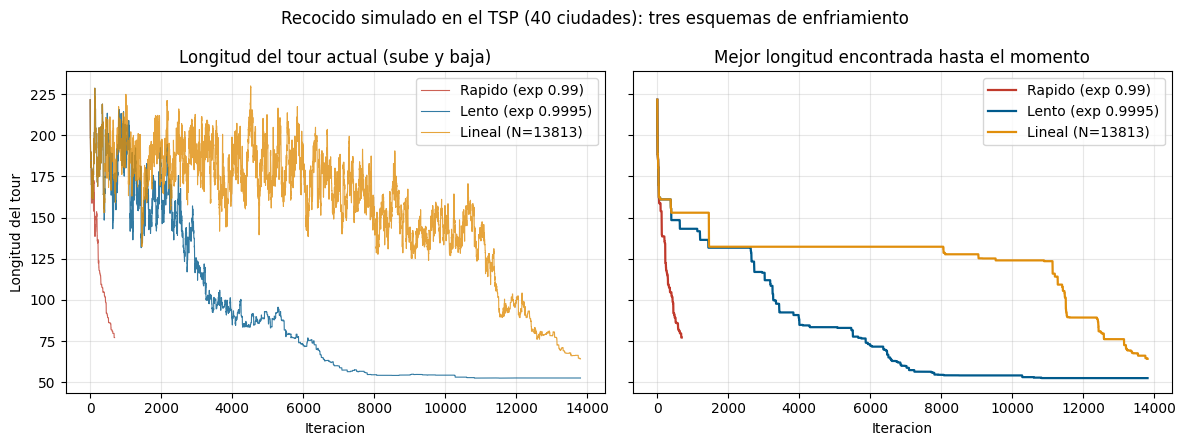

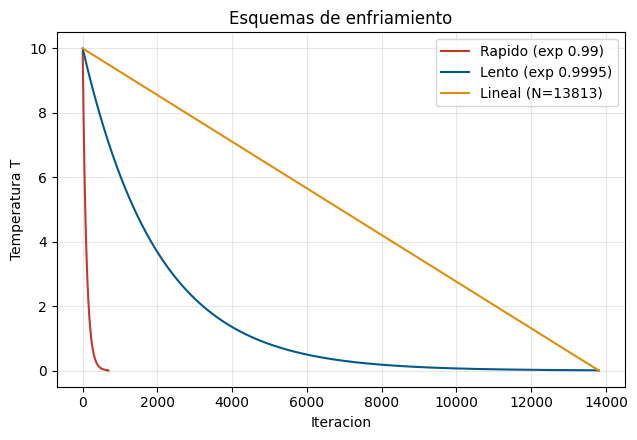

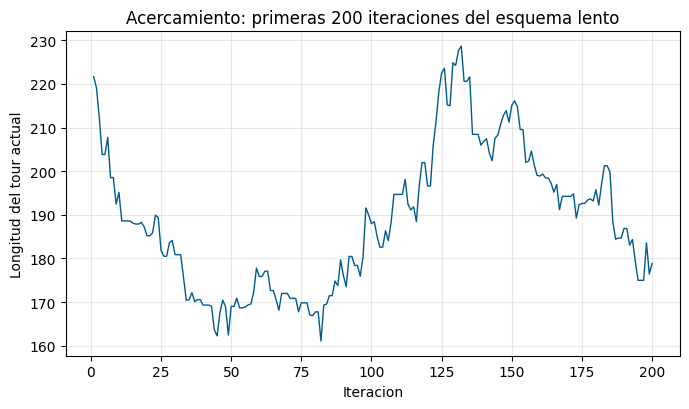

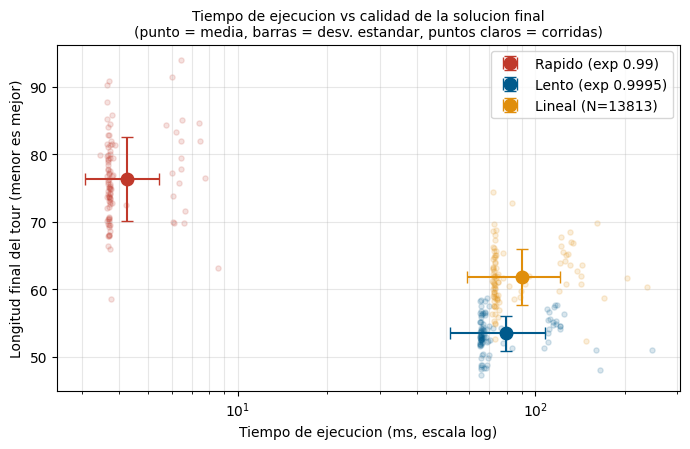

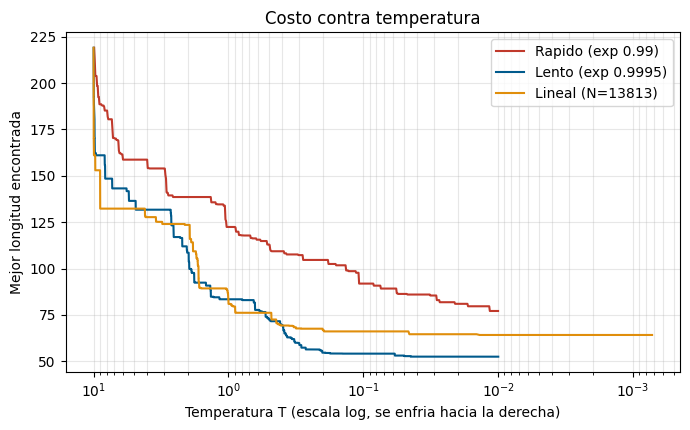

In [12]:
#Ejercicio No.4
import json
import math
import random
import statistics
import time

import matplotlib.pyplot as plt

EPS = 1e-9


def tour_length(points, route):
    return sum(math.dist(points[route[i]], points[route[(i + 1) % len(route)]])
               for i in range(len(route)))


def two_opt_move(route, i, k):
    return route[:i] + route[i:k + 1][::-1] + route[k + 1:]


def two_opt(points, route):
    route = route[:]
    n = len(route)
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for k in range(i + 1, n):
                a, b = points[route[i - 1]], points[route[i]]
                c, d = points[route[k]], points[route[(k + 1) % n]]
                delta = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
                if delta < -EPS:
                    route = two_opt_move(route, i, k)
                    improved = True
    return route


def exp_schedule(T0, alpha, Tmin):
    def schedule(t):
        T = T0 * alpha ** t
        return T if T > Tmin else 0.0
    return schedule


def linear_schedule(T0, N):
    def schedule(t):
        return T0 * (1 - t / N) if t < N else 0.0
    return schedule


def simulated_annealing(points, schedule, start, seed, log_first=0):
    rng = random.Random(seed)
    n = len(points)
    current = start[:]
    L = tour_length(points, current)
    best_L = L
    trace_current = [L]
    trace_best = [L]
    log = []
    t = 1
    while True:
        T = schedule(t)
        if T <= 0:
            break
        i, k = sorted(rng.sample(range(1, n), 2))
        while i == 1 and k == n - 1:
            i, k = sorted(rng.sample(range(1, n), 2))
        a, b = points[current[i - 1]], points[current[i]]
        c, d = points[current[k]], points[current[(k + 1) % n]]
        dL = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
        delta_E = -dL
        accepted = delta_E > 0 or rng.random() < math.exp(delta_E / T)
        if accepted:
            current = two_opt_move(current, i, k)
            L += dL
            if L < best_L:
                best_L = L
        if t <= log_first:
            log.append((t + 1, T, i, k, dL, accepted, L))
        trace_current.append(L)
        trace_best.append(best_L)
        t += 1
    return {"final": L, "best": best_L, "iterations": t - 1,
            "current": trace_current, "best_trace": trace_best, "log": log}


def random_instance(n, rng):
    return [(rng.uniform(0, 10), rng.uniform(0, 10)) for _ in range(n)]


def random_start(n, rng):
    route = list(range(n))
    rng.shuffle(route)
    return route


if __name__ == "__main__":
    T0, TMIN = 10.0, 0.01
    alpha_fast, alpha_slow = 0.99, 0.9995
    N = math.ceil(math.log(TMIN / T0) / math.log(alpha_slow))

    schedules = {
        "Rapido (exp 0.99)": exp_schedule(T0, alpha_fast, TMIN),
        "Lento (exp 0.9995)": exp_schedule(T0, alpha_slow, TMIN),
        f"Lineal (N={N})": linear_schedule(T0, N),
    }
    colors = ["#C0392B", "#005A8C", "#E08E0B"]

    n_cities = 40
    rng = random.Random(2024)
    points = random_instance(n_cities, rng)
    start = random_start(n_cities, rng)

    print(f"Instancia de {n_cities} ciudades. Longitud del tour inicial: {tour_length(points, start):.2f}")
    print(f"Iteraciones: rapido ~{math.ceil(math.log(TMIN / T0) / math.log(alpha_fast))}, "
          f"lento y lineal ~{N}\n")

    runs = {}
    for name, sched in schedules.items():
        t0 = time.perf_counter()
        runs[name] = simulated_annealing(points, sched, start, seed=1, log_first=10)
        runs[name]["time"] = time.perf_counter() - t0

    first = runs["Lento (exp 0.9995)"]
    print("Primeras iteraciones del esquema lento (iteracion 1 = tour inicial):")
    print(f"  iter  1: L = {first['current'][0]:.2f}  (tour inicial)")
    for it, T, i, k, dL, acc, L in first["log"]:
        sentido = "sin cambio" if abs(dL) < 1e-9 else ("empeoraria (sube)" if dL > 0 else "mejoraria (baja)")
        decision = "ACEPTADO" if acc else "rechazado"
        print(f"  iter {it:>2}: T={T:.3f}  invertir [{i},{k}]  cambio {dL:+.2f} -> {sentido}  {decision}  L = {L:.2f}")
    print()

    print("Comparacion con 10 instancias x 10 corridas por esquema:")
    stats = {name: {"final": [], "gap": [], "time": [], "iters": []} for name in schedules}
    hill = []
    for inst in range(10):
        r = random.Random(100 + inst)
        pts = random_instance(n_cities, r)
        per_inst = {name: [] for name in schedules}
        hc = []
        for rep in range(10):
            st = random_start(n_cities, r)
            hc.append(tour_length(pts, two_opt(pts, st)))
            for name, sched in schedules.items():
                t0 = time.perf_counter()
                res = simulated_annealing(pts, sched, st, seed=rep)
                dt = time.perf_counter() - t0
                per_inst[name].append((res["best"], dt, res["iterations"]))
        ref = min([b for v in per_inst.values() for b, _, _ in v] + hc)
        for name in schedules:
            for b, dt, it in per_inst[name]:
                stats[name]["final"].append(b)
                stats[name]["gap"].append((b - ref) / ref * 100)
                stats[name]["time"].append(dt * 1000)
                stats[name]["iters"].append(it)
        hill.extend((h - ref) / ref * 100 for h in hc)

    print(f"{'Esquema':<22}{'Iteraciones':>12}{'Tiempo (ms)':>13}{'Longitud media':>16}{'Brecha media':>14}")
    for name in schedules:
        s = stats[name]
        print(f"{name:<22}{statistics.mean(s['iters']):>12.0f}{statistics.mean(s['time']):>13.1f}"
              f"{statistics.mean(s['final']):>16.2f}{statistics.mean(s['gap']):>13.2f}%")
    print(f"{'2-opt (colinas)':<22}{'-':>12}{'-':>13}{'-':>16}{statistics.mean(hill):>13.2f}%")
    print("(brecha = % por encima del mejor tour encontrado en esa instancia por cualquier metodo)\n")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for (name, res), col in zip(runs.items(), colors):
        axes[0].plot(range(1, len(res["current"]) + 1), res["current"], color=col,
                     linewidth=0.8, alpha=0.8, label=name)
        axes[1].plot(range(1, len(res["best_trace"]) + 1), res["best_trace"], color=col,
                     linewidth=1.6, label=name)
    axes[0].set_title("Longitud del tour actual (sube y baja)")
    axes[1].set_title("Mejor longitud encontrada hasta el momento")
    for ax in axes:
        ax.set_xlabel("Iteracion")
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel("Longitud del tour")
    fig.suptitle(f"Recocido simulado en el TSP ({n_cities} ciudades): tres esquemas de enfriamiento")
    fig.tight_layout()
    fig.savefig("sa_curvas.png", dpi=150)

    plt.figure(figsize=(6.5, 4.5))
    for (name, sched), col in zip(schedules.items(), colors):
        ts = range(1, runs[name]["iterations"] + 2)
        plt.plot(list(ts), [sched(t) for t in ts], color=col, label=name)
    plt.xlabel("Iteracion")
    plt.ylabel("Temperatura T")
    plt.title("Esquemas de enfriamiento")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("sa_temperatura.png", dpi=150)

    zoom = runs["Lento (exp 0.9995)"]["current"][:200]
    plt.figure(figsize=(7, 4.2))
    plt.plot(range(1, len(zoom) + 1), zoom, color="#005A8C", linewidth=1)
    plt.xlabel("Iteracion")
    plt.ylabel("Longitud del tour actual")
    plt.title("Acercamiento: primeras 200 iteraciones del esquema lento")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("sa_zoom.png", dpi=150)
    print("Graficas guardadas: sa_curvas.png, sa_temperatura.png, sa_zoom.png")

    print()
    print("Comprobacion: el esquema lineal con T inicial mas baja (10 instancias x 5 corridas)")
    variantes = {
        "Lineal T0=10": linear_schedule(10.0, N),
        "Lineal T0=2": linear_schedule(2.0, N),
        "Exp lento T0=10": exp_schedule(10.0, alpha_slow, TMIN),
    }
    gaps = {k: [] for k in variantes}
    for inst in range(10):
        r = random.Random(500 + inst)
        pts = random_instance(n_cities, r)
        res = {k: [] for k in variantes}
        hc = []
        for rep in range(5):
            st = random_start(n_cities, r)
            hc.append(tour_length(pts, two_opt(pts, st)))
            for k, sched in variantes.items():
                res[k].append(simulated_annealing(pts, sched, st, seed=rep)["best"])
        ref = min([min(v) for v in res.values()] + hc)
        for k in variantes:
            gaps[k].extend((b - ref) / ref * 100 for b in res[k])
    for k, v in gaps.items():
        print(f"  {k:<18} brecha media {statistics.mean(v):6.2f}%")
    frac_lin = 1.0 / 10.0
    t_exp = math.log(10 / 1.0) / -math.log(alpha_slow)
    print(f"  Fraccion de iteraciones con T < 1: lineal (T0=10) {frac_lin:.0%}, "
          f"exponencial lento {(N - t_exp) / N:.0%}")

    fig, ax = plt.subplots(figsize=(7, 4.6))
    for (name, col) in zip(schedules, colors):
        st = stats[name]
        ax.scatter(st["time"], st["final"], color=col, alpha=0.15, s=14)
        ax.errorbar(statistics.mean(st["time"]), statistics.mean(st["final"]),
                    xerr=statistics.stdev(st["time"]), yerr=statistics.stdev(st["final"]),
                    fmt="o", color=col, markersize=9, capsize=4, label=name)
    ax.set_xscale("log")
    ax.set_xlabel("Tiempo de ejecucion (ms, escala log)")
    ax.set_ylabel("Longitud final del tour (menor es mejor)")
    ax.set_title("Tiempo de ejecucion vs calidad de la solucion final\n(punto = media, barras = desv. estandar, puntos claros = corridas)", fontsize=10)
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()
    fig.savefig("sa_tiempo_calidad.png", dpi=150)

    plt.figure(figsize=(7, 4.4))
    for (name, sched), col in zip(schedules.items(), colors):
        its = runs[name]["iterations"]
        temps = [sched(t) for t in range(1, its + 1)]
        plt.plot(temps, runs[name]["best_trace"][1:its + 1], color=col, label=name)
    plt.xscale("log")
    plt.gca().invert_xaxis()
    plt.xlabel("Temperatura T (escala log, se enfria hacia la derecha)")
    plt.ylabel("Mejor longitud encontrada")
    plt.title("Costo contra temperatura")
    plt.grid(alpha=0.3, which="both")
    plt.legend()
    plt.tight_layout()
    plt.savefig("sa_costo_temperatura.png", dpi=150)

    resumen = {name: {"iters": statistics.mean(stats[name]["iters"]),
                      "time": statistics.mean(stats[name]["time"]),
                      "final": statistics.mean(stats[name]["final"]),
                      "gap": statistics.mean(stats[name]["gap"])} for name in schedules}
    resumen["hill_gap"] = statistics.mean(hill)
    resumen["check"] = {k: statistics.mean(v) for k, v in gaps.items()}
    resumen["frac_exp"] = (N - t_exp) / N
    with open("ej4_stats.json", "w") as fh:
        json.dump(resumen, fh)
    print("Graficas adicionales: sa_tiempo_calidad.png, sa_costo_temperatura.png")
    plt.show()



Instancia 1 (detalle):
  MST aproximacion: [0, 5, 2, 3, 1, 7, 4, 6, 8]  L = 32.04
  peso del MST w(T) = 17.97   (cota inferior del optimo)
  despues de 2-opt:  [0, 1, 8, 7, 4, 6, 3, 2, 5]  L = 27.66  (4 mejoras)
  optimo (fuerza bruta): [0, 1, 8, 7, 4, 6, 3, 2, 5]  L = 27.66

Razon L / L_optimo en 100 instancias de 9 ciudades:
MST             media 1.126  mediana 1.114  desv. 0.092  min 1.000  max 1.329
MST + 2-opt     media 1.005  mediana 1.000  desv. 0.014  min 1.000  max 1.091

Instancias con ratio MST > 1.5: 0
Instancias donde 2-opt llega al optimo exacto: 85 de 100
Instancias donde 2-opt empeora: 0
Mejoras promedio de 2-opt sobre el tour MST: 2.55
Reduccion media de longitud con 2-opt: 10.2%

Verificaciones de la teoria (en las 100 instancias):
  w(T) <= OPT                              : 100 de 100
  w(T) <= OPT - arista mas larga del optimo : 100 de 100
  L_MST <= 2 w(T)                           : 100 de 100
  L_MST <= 2 OPT                            : 100 de 100
  razon w(T)/

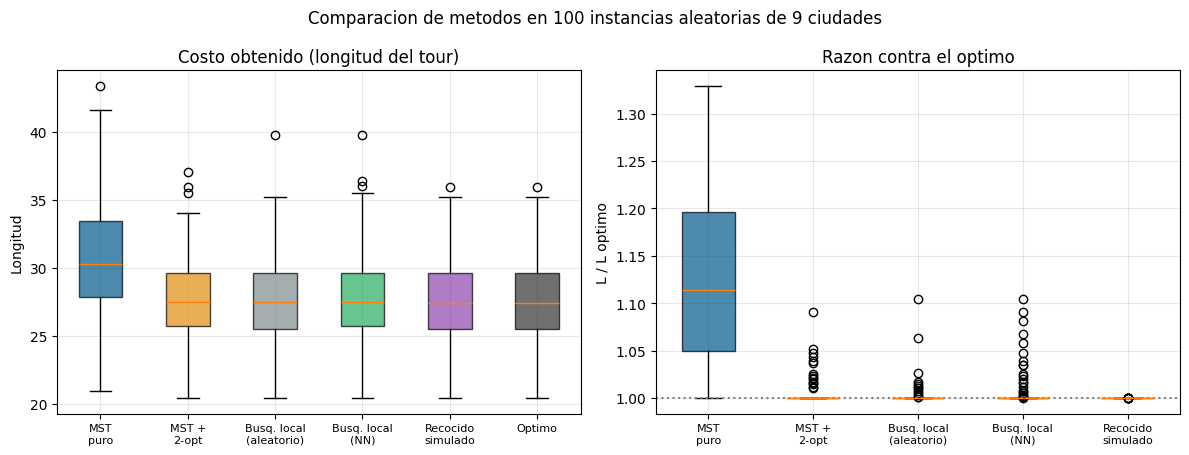

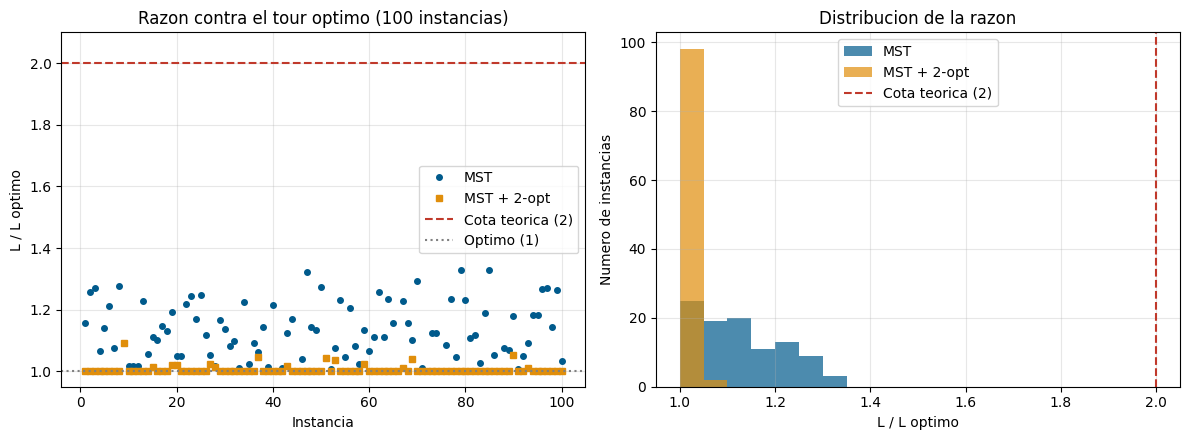

In [13]:
#Ejercicio No.5
import itertools
import math
import random
import statistics

import matplotlib.pyplot as plt

EPS = 1e-9


def mst_prim(points):
    best = {v: (math.dist(points[0], points[v]), 0) for v in range(1, len(points))}
    children = {v: [] for v in range(len(points))}
    while best:
        v = min(best, key=lambda u: best[u][0])
        children[best.pop(v)[1]].append(v)
        for u in best:
            d = math.dist(points[v], points[u])
            if d < best[u][0]:
                best[u] = (d, v)
    return children


def preorder(children, root=0):
    return [root] + [c for child in children[root] for c in preorder(children, child)]


def tour_length(points, tour):
    return sum(math.dist(points[tour[i]], points[tour[(i + 1) % len(tour)]])
               for i in range(len(tour)))


def mst_weight(points, children):
    return sum(math.dist(points[p], points[c]) for p, cs in children.items() for c in cs)


def two_opt_move(route, i, k):
    return route[:i] + route[i:k + 1][::-1] + route[k + 1:]


def two_opt(points, route):
    route = route[:]
    n = len(route)
    improvements = 0
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 1):
            for k in range(i + 1, n):
                a, b = points[route[i - 1]], points[route[i]]
                c, d = points[route[k]], points[route[(k + 1) % n]]
                delta = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
                if delta < -EPS:
                    route = two_opt_move(route, i, k)
                    improvements += 1
                    improved = True
    return route, improvements


def nearest_neighbour(points, start):
    unvisited = set(range(len(points))) - {start}
    route = [start]
    while unvisited:
        last = points[route[-1]]
        nxt = min(unvisited, key=lambda j: math.dist(last, points[j]))
        route.append(nxt)
        unvisited.remove(nxt)
    return route


def exp_schedule(T0, alpha, Tmin):
    def schedule(t):
        T = T0 * alpha ** t
        return T if T > Tmin else 0.0
    return schedule


def simulated_annealing(points, schedule, start, seed):
    rng = random.Random(seed)
    n = len(points)
    current = start[:]
    L = tour_length(points, current)
    best_L = L
    t = 1
    while True:
        T = schedule(t)
        if T <= 0:
            break
        i, k = sorted(rng.sample(range(1, n), 2))
        while i == 1 and k == n - 1:
            i, k = sorted(rng.sample(range(1, n), 2))
        a, b = points[current[i - 1]], points[current[i]]
        c, d = points[current[k]], points[current[(k + 1) % n]]
        dL = (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))
        if -dL > 0 or rng.random() < math.exp(-dL / T):
            current = two_opt_move(current, i, k)
            L += dL
            best_L = min(best_L, L)
        t += 1
    return best_L


def brute_force(points):
    n = len(points)
    D = [[math.dist(points[i], points[j]) for j in range(n)] for i in range(n)]
    best_tour, best_len = None, float("inf")
    for perm in itertools.permutations(range(1, n)):
        if perm[0] > perm[-1]:
            continue
        L = D[0][perm[0]] + D[perm[-1]][0]
        for i in range(n - 2):
            L += D[perm[i]][perm[i + 1]]
        if L < best_len:
            best_tour, best_len = (0,) + perm, L
    return best_tour, best_len


def longest_edge(points, tour):
    n = len(tour)
    return max(math.dist(points[tour[i]], points[tour[(i + 1) % n]]) for i in range(n))


if __name__ == "__main__":
    rng = random.Random(2024)
    instances = 100
    n_cities = 9

    rng2 = random.Random(99)
    sa_schedule = exp_schedule(10.0, 0.9995, 0.01)
    rows = []
    for idx in range(instances):
        pts = [(rng.uniform(0, 10), rng.uniform(0, 10)) for _ in range(n_cities)]
        children = mst_prim(pts)
        approx = preorder(children)
        wT = mst_weight(pts, children)
        L_mst = tour_length(pts, approx)
        improved, moves = two_opt(pts, approx)
        L_2opt = tour_length(pts, improved)
        opt_tour, L_opt = brute_force(pts)
        rt = list(range(n_cities))
        rng2.shuffle(rt)
        ls_rt_route, m_rt = two_opt(pts, rt)
        L_ls_rt = tour_length(pts, ls_rt_route)
        nn = nearest_neighbour(pts, rng2.randrange(n_cities))
        ls_nn_route, m_nn = two_opt(pts, nn)
        L_ls_nn = tour_length(pts, ls_nn_route)
        L_sa = simulated_annealing(pts, sa_schedule, rt, seed=idx)
        rows.append({
            "wT": wT, "L_mst": L_mst, "L_2opt": L_2opt, "L_opt": L_opt, "moves": moves,
            "bound_ok": wT <= L_opt + EPS,
            "tight_bound_ok": wT <= L_opt - longest_edge(pts, opt_tour) + EPS,
            "two_ok": L_mst <= 2 * wT + EPS,
            "ratio_mst": L_mst / L_opt, "ratio_2opt": L_2opt / L_opt,
            "L_ls_rt": L_ls_rt, "L_ls_nn": L_ls_nn, "L_sa": L_sa, "m_rt": m_rt, "m_nn": m_nn,
        })
        if idx == 0:
            print("Instancia 1 (detalle):")
            print(f"  MST aproximacion: {approx}  L = {L_mst:.2f}")
            print(f"  peso del MST w(T) = {wT:.2f}   (cota inferior del optimo)")
            print(f"  despues de 2-opt:  {improved}  L = {L_2opt:.2f}  ({moves} mejoras)")
            print(f"  optimo (fuerza bruta): {list(opt_tour)}  L = {L_opt:.2f}")
            print()

    r_m = [r["ratio_mst"] for r in rows]
    r_2 = [r["ratio_2opt"] for r in rows]

    def resumen(nombre, v):
        print(f"{nombre:<14}  media {statistics.mean(v):.3f}  mediana {statistics.median(v):.3f}  "
              f"desv. {statistics.stdev(v):.3f}  min {min(v):.3f}  max {max(v):.3f}")

    print(f"Razon L / L_optimo en {instances} instancias de {n_cities} ciudades:")
    resumen("MST", r_m)
    resumen("MST + 2-opt", r_2)
    print()
    print(f"Instancias con ratio MST > 1.5: {sum(1 for x in r_m if x > 1.5)}")
    print(f"Instancias donde 2-opt llega al optimo exacto: {sum(1 for x in r_2 if x < 1 + 1e-9)} de {instances}")
    print(f"Instancias donde 2-opt empeora: {sum(1 for a, b in zip(r_m, r_2) if b > a + 1e-9)}")
    print(f"Mejoras promedio de 2-opt sobre el tour MST: {statistics.mean(r['moves'] for r in rows):.2f}")
    print(f"Reduccion media de longitud con 2-opt: {statistics.mean((r['L_mst'] - r['L_2opt']) / r['L_mst'] for r in rows):.1%}")
    print()
    print("Verificaciones de la teoria (en las 100 instancias):")
    print(f"  w(T) <= OPT                              : {sum(r['bound_ok'] for r in rows)} de {instances}")
    print(f"  w(T) <= OPT - arista mas larga del optimo : {sum(r['tight_bound_ok'] for r in rows)} de {instances}")
    print(f"  L_MST <= 2 w(T)                           : {sum(r['two_ok'] for r in rows)} de {instances}")
    print(f"  L_MST <= 2 OPT                            : {sum(1 for x in r_m if x <= 2 + 1e-9)} de {instances}")
    print(f"  razon w(T)/OPT: media {statistics.mean(r['wT'] / r['L_opt'] for r in rows):.3f}")

    print()
    print("Comparacion con los metodos previos (misma 100 instancias de 9 ciudades):")
    metodos = [
        ("MST puro", "L_mst"),
        ("MST + 2-opt", "L_2opt"),
        ("Busqueda local (aleatorio)", "L_ls_rt"),
        ("Busqueda local (NN)", "L_ls_nn"),
        ("Recocido simulado (lento)", "L_sa"),
    ]
    print(f"{'Metodo':<28}{'Razon media':>12}{'Mediana':>9}{'Maximo':>8}{'Optimo exacto':>15}{'Costo medio':>13}")
    for nombre, clave in metodos:
        rs = [r[clave] / r["L_opt"] for r in rows]
        cm = statistics.mean(r[clave] for r in rows)
        ex = sum(1 for x in rs if x < 1 + 1e-6)
        print(f"{nombre:<28}{statistics.mean(rs):>12.3f}{statistics.median(rs):>9.3f}{max(rs):>8.3f}{ex:>11} de {instances}{cm:>12.2f}")
    print(f"{'Optimo (fuerza bruta)':<28}{1.0:>12.3f}{1.0:>9.3f}{1.0:>8.3f}{'':>15}{statistics.mean(r['L_opt'] for r in rows):>13.2f}")

    print()
    print("Mejoras de 2-opt hasta el optimo local (media por instancia):")
    print(f"  desde el tour del MST      : {statistics.mean(r['moves'] for r in rows):.2f}")
    print(f"  desde Nearest Neighbour    : {statistics.mean(r['m_nn'] for r in rows):.2f}")
    print(f"  desde un tour aleatorio    : {statistics.mean(r['m_rt'] for r in rows):.2f}")

    etiquetas = ["MST\npuro", "MST +\n2-opt", "Busq. local\n(aleatorio)", "Busq. local\n(NN)", "Recocido\nsimulado"]
    claves = [c for _, c in metodos]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    datos_costo = [[r[c] for r in rows] for c in claves] + [[r["L_opt"] for r in rows]]
    datos_razon = [[max(1.0, r[c] / r["L_opt"]) for r in rows] for c in claves]
    colores = ["#005A8C", "#E08E0B", "#7F8C8D", "#27AE60", "#8E44AD", "#333333"]
    for ax, datos, labs, titulo, yl in [
        (axes[0], datos_costo, etiquetas + ["Optimo"], "Costo obtenido (longitud del tour)", "Longitud"),
        (axes[1], datos_razon, etiquetas, "Razon contra el optimo", "L / L optimo"),
    ]:
        bp = ax.boxplot(datos, tick_labels=labs, patch_artist=True)
        for patch, col in zip(bp["boxes"], colores):
            patch.set_facecolor(col)
            patch.set_alpha(0.7)
        ax.set_title(titulo)
        ax.set_ylabel(yl)
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(alpha=0.3)
    axes[1].axhline(1, color="gray", linestyle=":")
    fig.suptitle("Comparacion de metodos en 100 instancias aleatorias de 9 ciudades")
    fig.tight_layout()
    fig.savefig("comparacion_metodos.png", dpi=150)
    print("Grafica guardada: comparacion_metodos.png")

    xs = range(1, instances + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(xs, r_m, "o", color="#005A8C", markersize=4, label="MST")
    axes[0].plot(xs, r_2, "s", color="#E08E0B", markersize=4, label="MST + 2-opt")
    axes[0].axhline(2, color="#C0392B", linestyle="--", label="Cota teorica (2)")
    axes[0].axhline(1, color="gray", linestyle=":", label="Optimo (1)")
    axes[0].set_xlabel("Instancia")
    axes[0].set_ylabel("L / L optimo")
    axes[0].set_ylim(0.95, 2.1)
    axes[0].set_title("Razon contra el tour optimo (100 instancias)")
    axes[0].grid(alpha=0.3)
    axes[0].legend(loc="center right")

    bins = [1 + 0.05 * i for i in range(0, 21)]
    r_m_h = [max(1.0, x) for x in r_m]
    r_2_h = [max(1.0, x) for x in r_2]
    axes[1].hist(r_m_h, bins=bins, alpha=0.7, color="#005A8C", label="MST")
    axes[1].hist(r_2_h, bins=bins, alpha=0.7, color="#E08E0B", label="MST + 2-opt")
    axes[1].axvline(2, color="#C0392B", linestyle="--", label="Cota teorica (2)")
    axes[1].set_xlabel("L / L optimo")
    axes[1].set_ylabel("Numero de instancias")
    axes[1].set_title("Distribucion de la razon")
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    fig.tight_layout()
    fig.savefig("ratio_mst.png", dpi=150)
    print("\nGrafica guardada: ratio_mst.png")
    plt.show()
